# Dataset Loading & Preprocessing

In [3]:
# Import necessary libraries
import tensorflow as tf
from pathlib import Path
import matplotlib.pyplot as plt

In [4]:
# 1. Define paths and basic hyperparameters
TRAIN_DIR = Path("Data/train")
TEST_DIR = Path("Data/test")
IMG_SIZE = (160, 160)
BATCH_SIZE = 32
SEED = 42
EPOCHS = 10

In [5]:
# 2. Load training dataset with an 80-20 split (Training subset)
train_dataset = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    validation_split=0.2,
    subset="training",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True
)

# 3. Load validation dataset (Validation subset)
val_dataset = tf.keras.utils.image_dataset_from_directory(
    TRAIN_DIR,
    validation_split=0.2,
    subset="validation",
    seed=SEED,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=True
)

# 4. Load test dataset for final evaluation
test_dataset = tf.keras.utils.image_dataset_from_directory(
    TEST_DIR,
    image_size=IMG_SIZE,
    batch_size=BATCH_SIZE,
    shuffle=False
)

Found 17526 files belonging to 2 classes.
Using 14021 files for training.
Found 17526 files belonging to 2 classes.
Using 3505 files for validation.
Found 2290 files belonging to 2 classes.


# Visualizing the Data

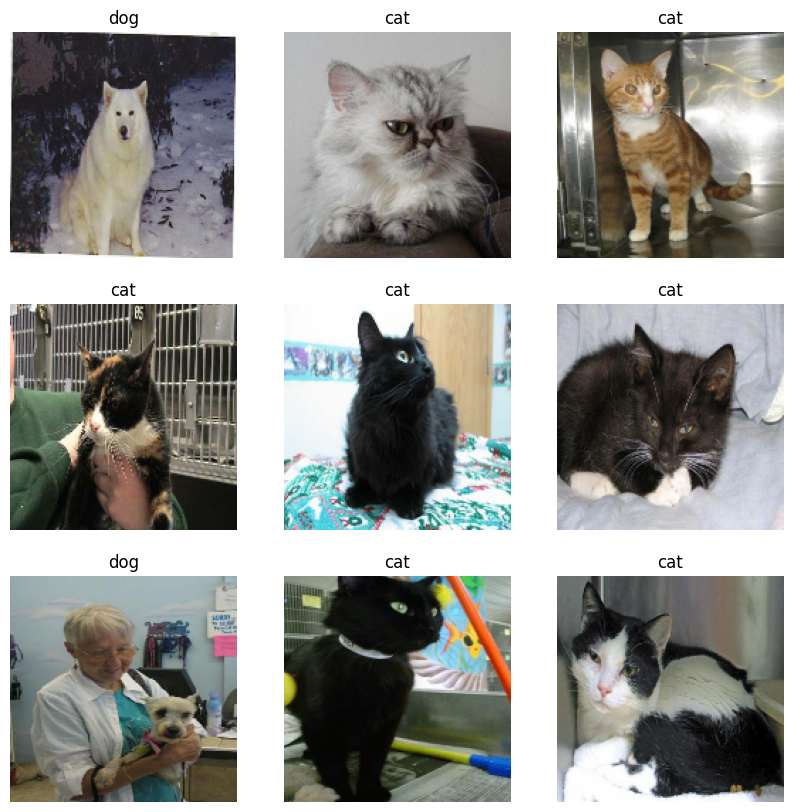

In [11]:
class_names = train_dataset.class_names
plt.figure(figsize=(10,10))
for images,labels in train_dataset.take(1):
    for i in range(9):
        ax = plt.subplot(3,3,i+1)
        plt.imshow(images[i].numpy().astype('uint8'))
        label_index = labels[i].numpy()
        plt.title(f"{class_names[label_index]}")
        plt.axis("off")
plt.show()

# CNN Model Architecture

In [6]:
# 5. Build the CNN model architecture sequentially
model = tf.keras.models.Sequential([
    # Rescale pixel values from [0, 255] to [0.0, 1.0]
    tf.keras.layers.Rescaling(1./255, input_shape=(160, 160, 3)),
    
    # First Convolutional Block
    tf.keras.layers.Conv2D(32, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    
    # Second Convolutional Block
    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    
    # Third Convolutional Block
    tf.keras.layers.Conv2D(64, (3, 3), activation='relu'),
    tf.keras.layers.MaxPooling2D((2, 2)),
    
    # Flatten layer to convert 2D maps to 1D vector
    tf.keras.layers.Flatten(),
    
    # Dense hidden layer
    tf.keras.layers.Dense(64, activation='relu'),
    
    # Output layer for binary classification (Cat vs Dog)
    tf.keras.layers.Dense(1, activation='sigmoid')
])

c:\Users\arifv\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\layers\preprocessing\data_layer.py:95: UserWarning: Do not pass an `input_shape`/`input_dim` argument to a layer. When using Sequential models, prefer using an `Input(shape)` object as the first layer in the model instead.
  super().__init__(**kwargs)


In [7]:
# 6. Compile the model
model.compile(
    optimizer='adam',
    loss='binary_crossentropy',
    metrics=['accuracy']
)

# Display model summary
model.summary()

print("Starting model training...")

Model: "sequential"

┏━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━━━━━━━━━━┳━━━━━━━━━━━━━━━┓
┃ Layer (type)                    ┃ Output Shape           ┃       Param # ┃
┡━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━━━━━━━━━━╇━━━━━━━━━━━━━━━┩
│ rescaling (Rescaling)           │ (None, 160, 160, 3)    │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d (Conv2D)                 │ (None, 158, 158, 32)   │           896 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d (MaxPooling2D)    │ (None, 79, 79, 32)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_1 (Conv2D)               │ (None, 77, 77, 64)     │        18,496 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_1 (MaxPooling2D)  │ (None, 38, 38, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ conv2d_2 (Conv2D)               │ (None, 36, 36, 64)     │        36,928 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ max_pooling2d_2 (MaxPooling2D)  │ (None, 18, 18, 64)     │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ flatten (Flatten)               │ (None, 20736)          │             0 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense (Dense)                   │ (None, 64)             │     1,327,168 │
├─────────────────────────────────┼────────────────────────┼───────────────┤
│ dense_1 (Dense)                 │ (None, 1)              │            65 │
└─────────────────────────────────┴────────────────────────┴───────────────┘

 Total params: 1,383,553 (5.28 MB)

 Trainable params: 1,383,553 (5.28 MB)

 Non-trainable params: 0 (0.00 B)

Starting model training...


# Training, Evaluation & Saving

In [8]:
history = model.fit(
    train_dataset,
    validation_data=val_dataset,
    epochs=EPOCHS
)

Epoch 1/10


c:\Users\arifv\AppData\Local\Programs\Python\Python313\Lib\site-packages\keras\src\trainers\epoch_iterator.py:74: UserWarning: `shuffle=True` was passed, but will be ignored since the data `x` was provided as a tf.data.Dataset. The Dataset is expected to already be shuffled (via `.shuffle(buffer_size)`).
  self.data_adapter = data_adapters.get_data_adapter(


439/439 ━━━━━━━━━━━━━━━━━━━━ 107s 239ms/step - accuracy: 0.7168 - loss: 0.5738 - val_accuracy: 0.7438 - val_loss: 0.5600
Epoch 2/10
439/439 ━━━━━━━━━━━━━━━━━━━━ 88s 200ms/step - accuracy: 0.7773 - loss: 0.4792 - val_accuracy: 0.7943 - val_loss: 0.4636
Epoch 3/10
439/439 ━━━━━━━━━━━━━━━━━━━━ 98s 222ms/step - accuracy: 0.8176 - loss: 0.4063 - val_accuracy: 0.8120 - val_loss: 0.4617
Epoch 4/10
439/439 ━━━━━━━━━━━━━━━━━━━━ 92s 209ms/step - accuracy: 0.8478 - loss: 0.3485 - val_accuracy: 0.8205 - val_loss: 0.4416
Epoch 5/10
439/439 ━━━━━━━━━━━━━━━━━━━━ 80s 182ms/step - accuracy: 0.8823 - loss: 0.2782 - val_accuracy: 0.7923 - val_loss: 0.4722
Epoch 6/10
439/439 ━━━━━━━━━━━━━━━━━━━━ 80s 182ms/step - accuracy: 0.9172 - loss: 0.2034 - val_accuracy: 0.8220 - val_loss: 0.5338
Epoch 7/10
439/439 ━━━━━━━━━━━━━━━━━━━━ 81s 185ms/step - accuracy: 0.9449 - loss: 0.1402 - val_accuracy: 0.8205 - val_loss: 0.6428
Epoch 8/10
439/439 ━━━━━━━━━━━━━━━━━━━━ 83s 189ms/step - accuracy: 0.9655 - loss: 0.0932 - va

In [9]:
# 8. Evaluate model performance using test data
test_loss, test_acc = model.evaluate(test_dataset)
print(f"Test Accuracy: {test_acc * 100:.2f}%")
print(f"Test Loss: {test_loss:.4f}")

72/72 ━━━━━━━━━━━━━━━━━━━━ 7s 93ms/step - accuracy: 0.7686 - loss: 1.3502
Test Accuracy: 76.86%
Test Loss: 1.3502


# Visualize the prediction

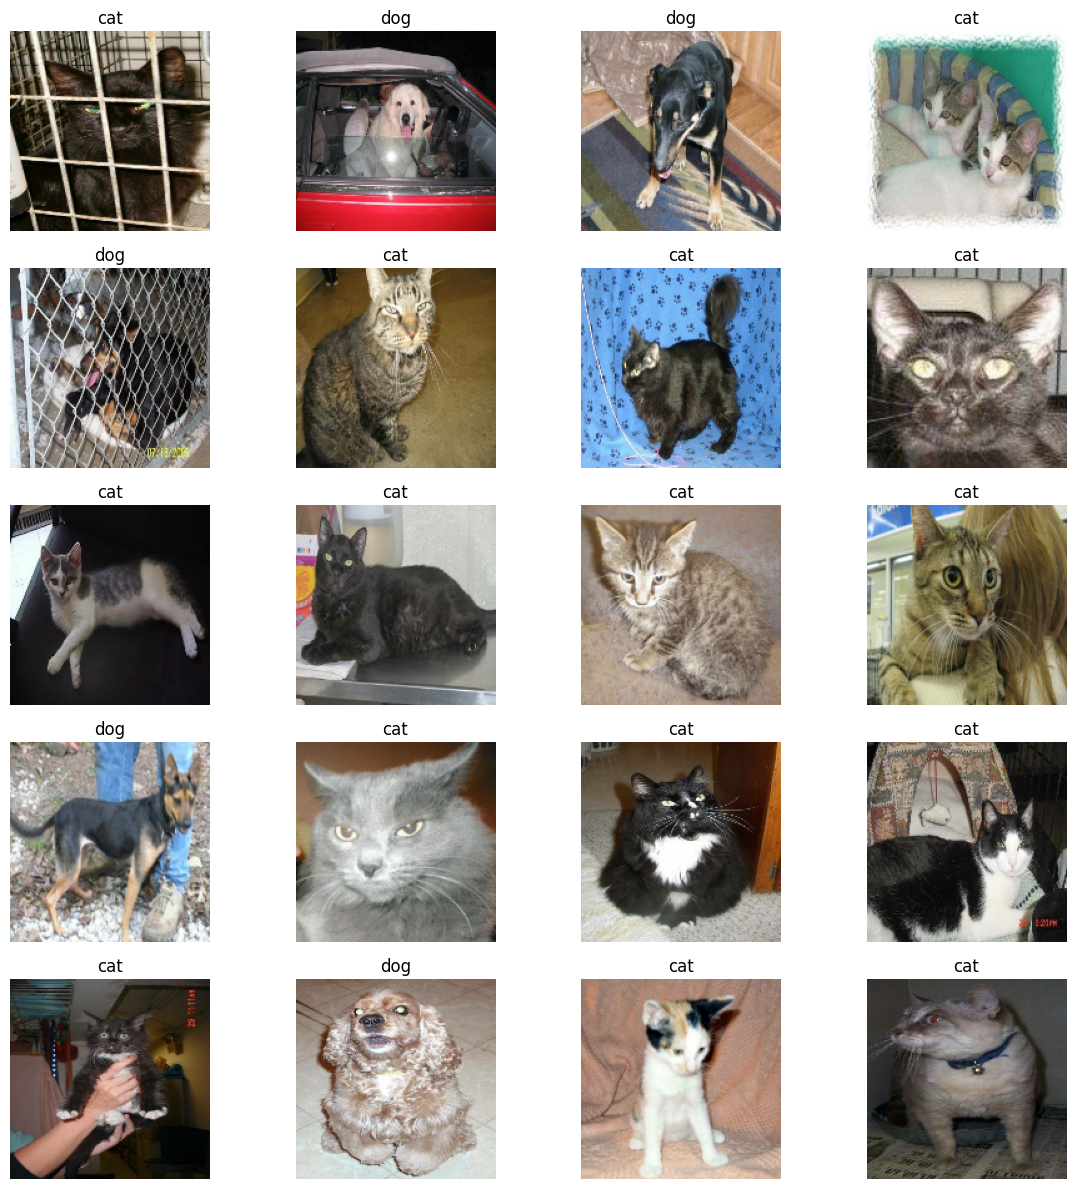

In [13]:
import matplotlib.pyplot as plt

# Set the overall figure size for the image grid (12x12 inches)
plt.figure(figsize=(12, 12))

# Retrieve the class names (Cat, Dog) from the training dataset
class_names = train_dataset.class_names

# Fetch a single batch of images and labels from the dataset
for images, labels in train_dataset.take(1):

    # Define the total number of images you want to display in the grid
    num_images_to_show = 20 
    
    # Loop through and plot each image up to the specified limit
    for i in range(num_images_to_show):
        
        # Create a subplot grid of 5 rows and 4 columns (5 x 4 = 20 subplots)
        ax = plt.subplot(5, 4, i + 1)
        
        # Convert tensor pixel values to uint8 and display the image
        plt.imshow(images[i].numpy().astype("uint8"))
        
        # Get the label index and set the corresponding class name as the title
        label_index = labels[i].numpy()
        plt.title(f"{class_names[label_index]}")
        
        # Hide the axis ticks and borders for a cleaner look
        plt.axis("off")

# Adjust layout to prevent overlapping titles and images
plt.tight_layout()

# Display the final plotted grid of images
plt.show()

# Save the trained model

In [14]:
# 9. Save the trained model to disk
models_dir = Path("models")
models_dir.mkdir(exist_ok=True)
model_path = models_dir / "cat_dog_cnn_model.keras"
model.save(model_path)
print(f"Model successfully saved to {model_path}")

Model successfully saved to models\cat_dog_cnn_model.keras
